In [ ]:
import pandas as pd
import numpy as np
stores=pd.read_excel('RetailPulse_Dataset.xlsx',sheet_name='stores')
products=pd.read_excel('RetailPulse_Dataset.xlsx',sheet_name='products')
sales=pd.read_excel('RetailPulse_Dataset.xlsx',sheet_name='sales_transactions')
inventory=pd.read_excel('RetailPulse_Dataset.xlsx',sheet_name='inventory_snapshots')

print("Stores Info")
stores.info()

print("\n products info")
products.info()

print("\n sales info")
sales.info()

print("\n inventory info")
inventory.info()

In [ ]:
sales['Date_Parsed']=pd.to_datetime(sales['date'],errors='coerce')
c=sales['Date_Parsed'].isna().sum()
print(c)

In [ ]:
j=0
sum=0
for i in sales['Date_Parsed'].isna():
    if i is True:
        print(f"{j}",i)
        sum+=1
    j+=1

In [ ]:
mask=sales['Date_Parsed'].isna()
print(mask)

In [ ]:
filtered_sales = sales[sales['Date_Parsed'].isna()]
print(filtered_sales['date'].head(10))


In [ ]:
mask=sales['Date_Parsed'].isna()
sales.loc[mask,'Date_Parsed']=pd.to_datetime(sales.loc[mask,'date'],dayfirst=True,errors='coerce')
sales['date']=sales['Date_Parsed']

In [ ]:
print(sales['date'])
# sales = sales.drop(columns=['Date_Parsed'])



In [ ]:
sales.columns

In [ ]:
print(sales['qty'].isna().sum())
print(sales['revenue'].isna().sum())

In [ ]:
both_missing=sales[sales['qty'].isna() & sales['revenue'].isna()]
print(both_missing)

In [ ]:
sales=sales[~(sales['qty'].isna() & sales['revenue'].isna())]
counts=0


len(sales)

In [ ]:
sales=sales.merge(products[['product_id','sell_price']],on='product_id',how='left')

sales.head(5)

In [ ]:
sales.head(5)
sales=sales.rename(columns={'sell_price_x':'sell_price'})

In [ ]:
sales.head(5)

In [ ]:
sales.head(5)

In [ ]:
print(sales['sell_price'].isna().sum())
# print(sales.loc[mask_b, 'product_id'].nunique())

In [ ]:
mask_b=sales['qty'].notna() & sales['revenue'].isna()
#print(mask_b)
sales.loc[mask_b,'revenue']=sales.loc[mask_b,'qty']*sales.loc[mask_b,'sell_price']
print(sales['revenue'].isna().sum())
mask_b.sum()

In [ ]:
sales.loc[mask_b, ['qty','sell_price','revenue']].head(10)

In [ ]:
print(sales['sell_price'].isna().sum())
print(sales.loc[mask_b, 'product_id'].nunique())

In [ ]:
products = pd.read_excel("RetailPulse_Dataset.xlsx", sheet_name="products")

In [ ]:
sample=products[products['sell_price'].isna()]
sample
# products.shape
# products.info()

In [ ]:
grocery=products[products['category']=='Grocery'].dropna()
grocery
grocery['margin_ratio']=grocery['sell_price']/grocery['cost_price']
grocery['margin_ratio'].mean()


In [ ]:
print(sales['sell_price'].isna().sum())

In [ ]:
avg_margin = grocery['margin_ratio'].mean()
products.loc[products['product_id'] == 'P0026', 'sell_price'] = 755.47 * avg_margin
products[products['product_id'] == 'P0026']

In [55]:
products['sell_price'].isna().sum()

np.int64(0)

In [47]:
print(sales['sell_price'].isna().sum())
print(sales.loc[mask_b, 'product_id'].nunique())

118
1


In [ ]:
sales=sales.drop(columns=['Date_Parsed'])


In [52]:
sales.merge(products[['product_id','sell_price']],on='product_id',how='left')


,txn_id,store_id,product_id,date,qty,revenue,sell_price_x,sell_price_y
0,TXN0011583,ST002,P0019,2025-07-25,1.0,748.33,748.33,748.33
1,TXN0003250,ST009,P0062,2025-02-27,2.0,1433.82,716.91,716.91
2,TXN0001933,ST009,P0099,2025-02-03,2.0,1825.12,912.56,912.56
3,TXN0000460,ST010,P0066,2025-01-08,3.0,679.98,226.66,226.66
4,TXN0008811,ST004,P0101,2025-06-06,1.0,921.83,921.83,921.83
...,...,...,...,...,...,...,...,...
16031,TXN0003047,ST010,P0085,2025-02-23,1.0,1215.61,1215.61,1215.61
16032,TXN0009918,ST010,P0036,2025-06-24,3.0,1234.98,411.66,411.66
16033,TXN0004080,ST006,P0096,2025-03-14,2.0,1418.92,709.46,709.46
16034,TXN0002255,ST001,P0091,2025-02-10,3.0,1064.64,354.88,354.88


In [54]:
# sales['sell_price_y'].isna().sum()
sales.info()
sales[sales['sell_price'].isna()]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16036 entries, 0 to 16035
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   txn_id      16036 non-null  object        
 1   store_id    16036 non-null  object        
 2   product_id  16036 non-null  object        
 3   date        16036 non-null  datetime64[ns]
 4   qty         16036 non-null  float64       
 5   revenue     15918 non-null  float64       
 6   sell_price  15918 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 877.1+ KB


,txn_id,store_id,product_id,date,qty,revenue,sell_price
18,TXN0003014,ST006,P0026,2025-02-23,5.0,NaN,NaN
79,TXN0015830,ST006,P0026,2025-09-27,1.0,NaN,NaN
784,TXN0007820,ST007,P0026,2025-05-19,2.0,NaN,NaN
898,TXN0009459,ST002,P0026,2025-06-17,2.0,NaN,NaN
972,TXN0015002,ST008,P0026,2025-09-16,3.0,NaN,NaN
...,...,...,...,...,...,...,...
15456,TXN0011374,ST002,P0026,2025-07-21,5.0,NaN,NaN
15470,TXN0015154,ST007,P0026,2025-09-18,1.0,NaN,NaN
15575,TXN0007323,ST010,P0026,2025-05-10,2.0,NaN,NaN
15704,TXN0004818,ST003,P0026,2025-03-27,1.0,NaN,NaN


In [ ]:
sales=sales.rename(columns={'sell_price_y':'sell_price'})
sales=sales.drop(columns=['sell_price_x'])


In [ ]:
print((sales['qty'].isna() & sales['revenue'].notna()).sum())
print((sales['qty'].notna() & sales['revenue'].isna()).sum())
print((sales['qty'].isna() & sales['revenue'].isna()).sum())



In [ ]:
mask_b = sales['qty'].notna() & sales['revenue'].isna()
sales.loc[mask_b, 'revenue'] = sales.loc[mask_b, 'qty'] * sales.loc[mask_b, 'sell_price']

In [ ]:
mask_c=sales['qty'].isna() & sales['revenue'].notna()
sales.loc[mask_c,'qty']=sales.loc[mask_c,'revenue']/sales.loc[mask_c,'sell_price']

In [56]:
print(sales.columns.tolist())
print(sales['sell_price'].isna().sum())

['txn_id', 'store_id', 'product_id', 'date', 'qty', 'revenue', 'sell_price']
118


In [57]:
products[products['product_id'] == 'P0026']

,product_id,category,subcategory,cost_price,sell_price
25,P0026,Grocery,Flour,755.47,1055.560959


In [59]:
price_lookup = products.set_index('product_id')['sell_price']
sales['sell_price'] = sales['sell_price'].fillna(sales['product_id'].map(price_lookup))
print(sales['sell_price'].isna().sum())


0


In [ ]:
print((sales['qty'].isna() & sales['revenue'].notna()).sum())
print((sales['qty'].notna() & sales['revenue'].isna()).sum())
print((sales['qty'].isna() & sales['revenue'].isna()).sum())

0
118
0


In [62]:
mask_b = sales['qty'].notna() & sales['revenue'].isna()
sales.loc[mask_b, 'revenue'] = sales.loc[mask_b, 'qty'] * sales.loc[mask_b, 'sell_price']

In [63]:
print((sales['qty'].isna() & sales['revenue'].notna()).sum())
print((sales['qty'].notna() & sales['revenue'].isna()).sum())
print((sales['qty'].isna() & sales['revenue'].isna()).sum())

0
0
0


In [64]:
print(sales['qty'].isna().sum())
print(sales['revenue'].isna().sum())
print(sales['sell_price'].isna().sum())
print(len(sales))

0
0
0
16036


In [68]:
(sales['qty']<1).sum()

np.int64(96)

In [69]:
returns_df = sales[sales['revenue'] < 0].copy()
sales_clean = sales[sales['revenue'] >= 0].copy()

print(len(returns_df))
print(len(sales_clean))

96
15940


In [ ]:
inventory.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15600 entries, 0 to 15599
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   store_id       15600 non-null  object 
 1   product_id     15600 non-null  object 
 2   date           15600 non-null  object 
 3   stock_on_hand  15444 non-null  float64
 4   reorder_level  15600 non-null  int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 609.5+ KB


In [73]:
inventory[inventory['stock_on_hand'].isna()]
inventory['stock_on_hand'].isna().sum()

np.int64(156)

In [74]:
inventory = inventory.dropna(subset=['stock_on_hand'])
print(len(inventory))

15444


In [75]:
stores.info()
products.info()
sales.info()
inventory.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   store_id     10 non-null     object
 1   city         10 non-null     object
 2   area_type    10 non-null     object
 3   size_sqft    10 non-null     int64 
 4   opened_date  10 non-null     object
dtypes: int64(1), object(4)
memory usage: 532.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   product_id   114 non-null    object 
 1   category     114 non-null    object 
 2   subcategory  114 non-null    object 
 3   cost_price   113 non-null    float64
 4   sell_price   114 non-null    float64
dtypes: float64(2), object(3)
memory usage: 4.6+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16036 entries, 0 to 16035
Data columns (total 7 columns):

In [93]:
grocery = products[products['category'] == 'Grocery'].dropna()
grocery['margin_ratio']=grocery['sell_price']/grocery['cost_price']
grocery['margin_ratio'].mean()

np.float64(1.3972241906442207)

In [94]:
products[products['subcategory'] == 'Pulses']

,product_id,category,subcategory,cost_price,sell_price
5,P0006,Grocery,Pulses,95.44,146.15
6,P0007,Grocery,Pulses,490.91,742.85
7,P0008,Grocery,Pulses,589.19,819.74
8,P0009,Grocery,Pulses,779.03,1028.58
9,P0010,Grocery,Pulses,450.59,686.35
10,P0011,Grocery,Pulses,NaN,772.65
11,P0012,Grocery,Pulses,470.33,690.00


In [96]:
pulses = products[(products['subcategory'] == 'Pulses') & (products['product_id'] != 'P0011')].dropna()
pulses['margin_ratio'] = pulses['sell_price'] / pulses['cost_price']
print(grocery['margin_ratio'].mean())

1.3972241906442207


In [97]:
products.loc[products['product_id']=='P0011','cost_price']=products.loc[products['product_id']=='P0011','sell_price']/grocery['margin_ratio'].mean()

In [101]:
products[products['cost_price'].isna()].sum()

product_id       0
category         0
subcategory      0
cost_price     0.0
sell_price     0.0
dtype: object

In [103]:
products.info()
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   product_id   114 non-null    object 
 1   category     114 non-null    object 
 2   subcategory  114 non-null    object 
 3   cost_price   114 non-null    float64
 4   sell_price   114 non-null    float64
dtypes: float64(2), object(3)
memory usage: 4.6+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16036 entries, 0 to 16035
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   txn_id      16036 non-null  object        
 1   store_id    16036 non-null  object        
 2   product_id  16036 non-null  object        
 3   date        16036 non-null  datetime64[ns]
 4   qty         16036 non-null  float64       
 5   revenue     16036 non-null  float64       
 6   sell_price  16036 non-null  float64       
dtypes: da

In [102]:
master = sales_clean.merge(products, on='product_id', how='left')
master = master.merge(stores, on='store_id', how='left')

print(master.shape)
master.isna().sum()

(15940, 15)


txn_id          0
store_id        0
product_id      0
date            0
qty             0
revenue         0
sell_price_x    0
category        0
subcategory     0
cost_price      0
sell_price_y    0
city            0
area_type       0
size_sqft       0
opened_date     0
dtype: int64

In [104]:
(master['sell_price_x'] == master['sell_price_y']).all()

np.True_

In [105]:
master=master.drop(columns=['sell_price_y'])
master=master.rename(columns={'sell_price_x':'sell_price'})

In [106]:
master.columns

Index(['txn_id', 'store_id', 'product_id', 'date', 'qty', 'revenue',
       'sell_price', 'category', 'subcategory', 'cost_price', 'city',
       'area_type', 'size_sqft', 'opened_date'],
      dtype='object')

In [107]:
master.to_csv('master_clean.csv', index=False)
returns_df.to_csv('returns_clean.csv', index=False)

#Performing statistics

In [3]:
import pandas as pd
master = pd.read_csv("../data/processed/master_clean.csv")
returns_df = pd.read_csv("../data/processed/returns_clean.csv")
master.shape

(15940, 14)

In [4]:
store_revenue = master.groupby('store_id')['revenue'].agg(['sum', 'mean', 'std', 'count'])
store_revenue

,sum,mean,std,count
store_id,,,,
ST001,3.077825e+06,1341.100177,1217.964370,2295
ST002,2.494386e+06,1277.207256,1146.683423,1953
ST003,1.280695e+06,1279.415900,1112.744523,1001
ST004,2.108052e+06,1238.573697,1136.691632,1702
ST005,1.119481e+06,1288.240734,1177.164433,869
ST006,2.065863e+06,1387.416373,1237.229095,1489
ST007,2.395201e+06,1246.202230,1105.127635,1922
ST008,1.607169e+06,1338.192605,1191.255932,1201
ST009,2.717433e+06,1287.883060,1142.578926,2110


In [5]:
import numpy as np

store_revenue['se'] = store_revenue['std'] / np.sqrt(store_revenue['count'])
store_revenue['ci_lower'] = store_revenue['mean'] - 1.96 * store_revenue['se']
store_revenue['ci_upper'] = store_revenue['mean'] + 1.96 * store_revenue['se']

store_revenue[['mean', 'ci_lower', 'ci_upper', 'count']].sort_values('mean', ascending=False)

,mean,ci_lower,ci_upper,count
store_id,,,,
ST006,1387.416373,1324.573092,1450.259653,1489
ST001,1341.100177,1291.269210,1390.931143,2295
ST008,1338.192605,1270.819023,1405.566188,1201
ST010,1318.151227,1257.440762,1378.861692,1398
ST005,1288.240734,1209.972900,1366.508568,869
ST009,1287.883060,1239.130093,1336.636028,2110
ST003,1279.415900,1210.481739,1348.350062,1001
ST002,1277.207256,1226.350520,1328.063992,1953
ST007,1246.202230,1196.794850,1295.609609,1922


In [6]:
import numpy as np
np.random.seed(1)
data = np.random.normal(1000, 50, 1000)  # 1000 fake transactions, mean=1000, std=50

mean = data.mean()
std = data.std()
lower = mean - 1.96*std
upper = mean + 1.96*std

inside = ((data >= lower) & (data <= upper)).sum()
print(inside, "out of 1000 fell inside the range")

946 out of 1000 fell inside the range


In [7]:
store_info=master[['store_id','city','area_type','size_sqft']].drop_duplicates()
store_summary=store_revenue.merge(store_info,on='store_id')
store_summary.sort_values('mean', ascending=False)


,store_id,sum,mean,std,count,se,ci_lower,ci_upper,city,area_type,size_sqft
5,ST006,2.065863e+06,1387.416373,1237.229095,1489,32.062898,1324.573092,1450.259653,Tirunelveli,Urban,1800
0,ST001,3.077825e+06,1341.100177,1217.964370,2295,25.423962,1291.269210,1390.931143,Chennai,Semi-Urban,1800
7,ST008,1.607169e+06,1338.192605,1191.255932,1201,34.374277,1270.819023,1405.566188,Vellore,Semi-Urban,1800
9,ST010,1.842775e+06,1318.151227,1158.140039,1398,30.974727,1257.440762,1378.861692,Kanchipuram,Semi-Urban,3500
4,ST005,1.119481e+06,1288.240734,1177.164433,869,39.932568,1209.972900,1366.508568,Salem,Urban,3500
8,ST009,2.717433e+06,1287.883060,1142.578926,2110,24.873963,1239.130093,1336.636028,Thoothukudi,Urban,4200
2,ST003,1.280695e+06,1279.415900,1112.744523,1001,35.170491,1210.481739,1348.350062,Madurai,Urban,2200
1,ST002,2.494386e+06,1277.207256,1146.683423,1953,25.947314,1226.350520,1328.063992,Coimbatore,Semi-Urban,2600
6,ST007,2.395201e+06,1246.202230,1105.127635,1922,25.207847,1196.794850,1295.609609,Erode,Urban,2200
3,ST004,2.108052e+06,1238.573697,1136.691632,1702,27.552619,1184.570564,1292.576830,Trichy,Semi-Urban,4200


In [9]:
store_summary[['size_sqft','mean']].corr()

,size_sqft,mean
size_sqft,1.000000,-0.532325
mean,-0.532325,1.000000


In [11]:
store_summary.groupby('area_type')['mean'].mean()

area_type
Semi-Urban    1302.644992
Urban         1297.831659
Name: mean, dtype: float64

In [12]:
import pandas as pd
master = pd.read_csv("../data/processed/master_clean.csv")

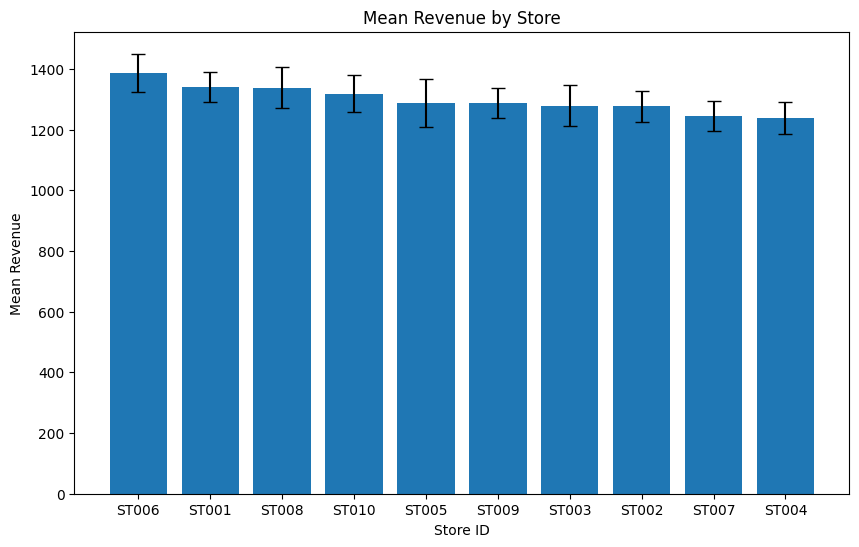

In [28]:
import matplotlib.pyplot as plt

store_summary_sorted=store_summary.sort_values('mean', ascending=False)
store_error=store_summary_sorted['ci_upper']-store_summary_sorted['mean']

plt.figure(figsize=(10,6))
plt.bar(store_summary_sorted['store_id'], store_summary_sorted['mean'], yerr=store_error, capsize=5)

plt.title('Mean Revenue by Store')
plt.xlabel('Store ID')
plt.ylabel('Mean Revenue')
plt.savefig("../reports/store_revenue_ci.png", dpi=150, bbox_inches='tight')
plt.show()


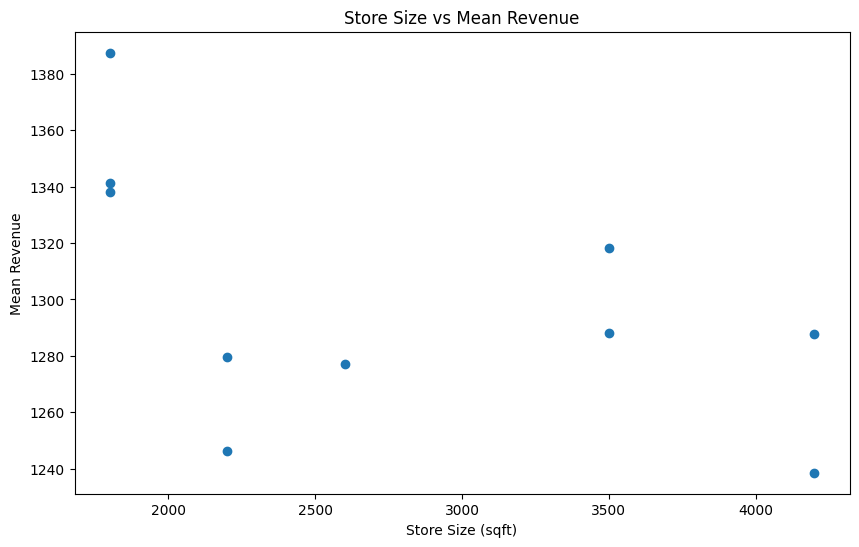

In [27]:
plt.figure(figsize=(10,6))
plt.scatter(store_summary_sorted['size_sqft'], store_summary_sorted['mean'])
plt.title('Store Size vs Mean Revenue')
plt.xlabel('Store Size (sqft)')
plt.ylabel('Mean Revenue')
plt.savefig("../reports/size_vs_revenue.png", dpi=150, bbox_inches='tight')
plt.show()


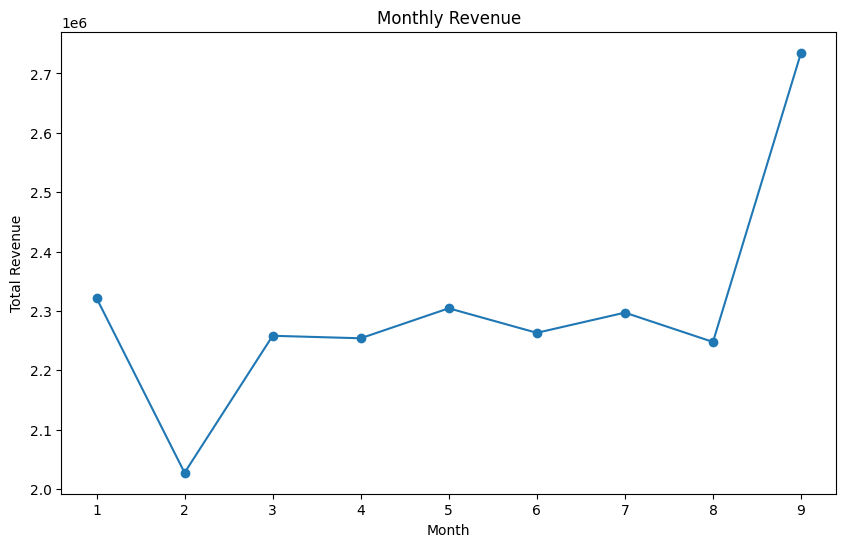

In [26]:
master['date']=pd.to_datetime(master['date'])
monthly_revenue=master.groupby(master['date'].dt.month)['revenue'].sum()

plt.figure(figsize=(10,6))
plt.plot(monthly_revenue.index,monthly_revenue.values,marker='o')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.savefig("../reports/monthly_revenue.png", dpi=150, bbox_inches='tight')
plt.show()



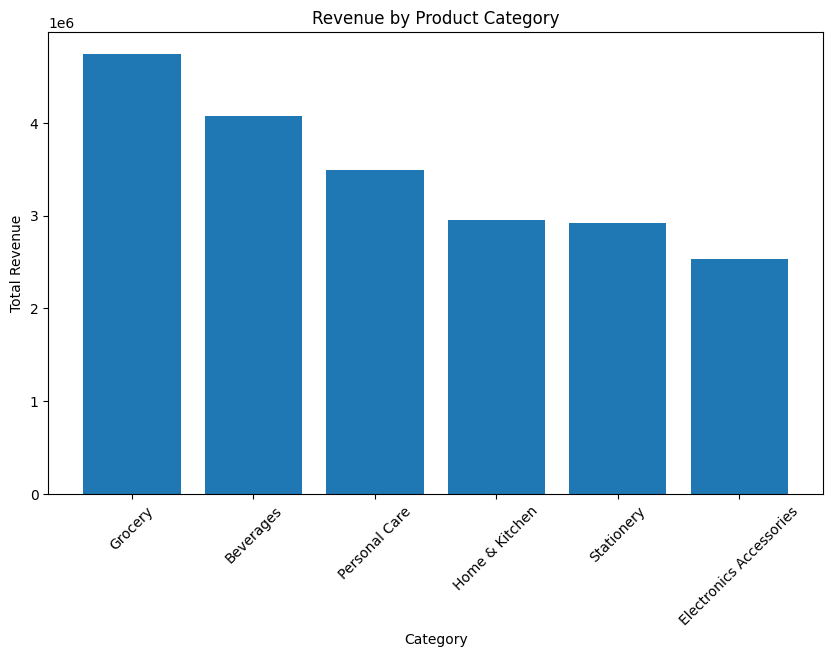

In [25]:
category_revenue=master.groupby('category')['revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,6))
plt.bar(category_revenue.index, category_revenue.values)
plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.savefig("../reports/category_revenue.png", dpi=150, bbox_inches='tight')
plt.show()
